In [ ]:

import numpy as np
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.layers import TextVectorization


In [ ]:

text = """
I love artificial intelligence
I love machine learning
Artificial intelligence is amazing
Machine learning is useful
I am learning deep learning
Deep learning uses neural networks
Transformers are powerful models
AI helps people solve problems
I love learning new technology
Technology makes life easier
"""

# Repeat text to create more training examples
text = text * 20

print(text)



I love artificial intelligence
I love machine learning
Artificial intelligence is amazing
Machine learning is useful
I am learning deep learning
Deep learning uses neural networks
Transformers are powerful models
AI helps people solve problems
I love learning new technology
Technology makes life easier

I love artificial intelligence
I love machine learning
Artificial intelligence is amazing
Machine learning is useful
I am learning deep learning
Deep learning uses neural networks
Transformers are powerful models
AI helps people solve problems
I love learning new technology
Technology makes life easier

I love artificial intelligence
I love machine learning
Artificial intelligence is amazing
Machine learning is useful
I am learning deep learning
Deep learning uses neural networks
Transformers are powerful models
AI helps people solve problems
I love learning new technology
Technology makes life easier

I love artificial intelligence
I love machine learning
Artificial intelligence is am

In [ ]:

vectorizer = TextVectorization(
    max_tokens=1000,
    output_mode="int",
    output_sequence_length=200
)

vectorizer.adapt([text])

words = vectorizer.get_vocabulary()
tokens = vectorizer([text]).numpy()[0]

# Remove padding zeros
tokens = tokens[tokens != 0]

print("Vocabulary:", words)
print("Token numbers:", tokens[:20])



Vocabulary: ['', '[UNK]', np.str_('learning'), np.str_('i'), np.str_('love'), np.str_('technology'), np.str_('machine'), np.str_('is'), np.str_('intelligence'), np.str_('deep'), np.str_('artificial'), np.str_('uses'), np.str_('useful'), np.str_('transformers'), np.str_('solve'), np.str_('problems'), np.str_('powerful'), np.str_('people'), np.str_('new'), np.str_('neural'), np.str_('networks'), np.str_('models'), np.str_('makes'), np.str_('life'), np.str_('helps'), np.str_('easier'), np.str_('are'), np.str_('amazing'), np.str_('am'), np.str_('ai')]
Token numbers: [ 3  4 10  8  3  4  6  2 10  8  7 27  6  2  7 12  3 28  2  9]


In [ ]:

sequence_length = 5

X = []
y = []

for i in range(len(tokens) - sequence_length):
    X.append(tokens[i:i + sequence_length])
    y.append(tokens[i + sequence_length])

X = np.array(X)
y = np.array(y)

print("Input shape:", X.shape)
print("Output shape:", y.shape)


Input shape: (195, 5)
Output shape: (195,)


In [ ]:

vocab_size = len(words)
embedding_dim = 64

# Input layer
inputs = layers.Input(shape=(sequence_length,))

# Convert words into embeddings
x = layers.Embedding(vocab_size, embedding_dim)(inputs)

# Add position information
positions = tf.range(start=0, limit=sequence_length, delta=1)
position_embedding = layers.Embedding(
    sequence_length, embedding_dim
)(positions)

x = x + position_embedding

# Self-attention layer
attention = layers.MultiHeadAttention(
    num_heads=2,
    key_dim=32
)(x, x, use_causal_mask=True)

x = layers.Add()([x, attention])
x = layers.LayerNormalization()(x)

# Feed-forward network
ffn = layers.Dense(128, activation="relu")(x)
ffn = layers.Dense(embedding_dim)(ffn)

x = layers.Add()([x, ffn])
x = layers.LayerNormalization()(x)

# Use last word position to predict next word
x = layers.Lambda(lambda a: a[:, -1, :])(x)

outputs = layers.Dense(vocab_size, activation="softmax")(x)

model = tf.keras.Model(inputs, outputs)

model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 5)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 5, 64)     │      1,920 │ input_layer[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 5, 64)     │          0 │ embedding[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 5, 64)     │     16,640 │ add[0][0],        │
│ (MultiHeadAttentio… │                   │            │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 5, 64)     │          0 │ add[0][0],        │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 5, 64)     │        128 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 5, 128)    │      8,320 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 5, 64)     │      8,256 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 5, 64)     │          0 │ layer_normalizat… │
│                     │                   │            │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 5, 64)     │        128 │ add_2[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda (Lambda)     │ (None, 64)        │          0 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 30)        │      1,950 │ lambda[0][0]      │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 37,342 (145.87 KB)

 Trainable params: 37,342 (145.87 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")


Model compiled successfully!


In [ ]:

history = model.fit(
    X,
    y,
    epochs=50,
    batch_size=16
)


Epoch 1/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.2513 - loss: 3.0119
Epoch 2/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7231 - loss: 1.2842
Epoch 3/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8256 - loss: 0.6613
Epoch 4/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8256 - loss: 0.4818
Epoch 5/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.8821 - loss: 0.3788
Epoch 6/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9538 - loss: 0.2601
Epoch 7/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9795 - loss: 0.1690
Epoch 8/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9897 - loss: 0.1133
Epoch 9/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9846 - loss: 0.0916
Epoch 10/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 1.0000 - loss: 0.0653
Epoch 11/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 1.0000 - loss: 0.0523
Epoch 12/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy:

In [ ]:

sentence = "I love artificial intelligence is"

# Convert sentence into numbers
input_tokens = vectorizer([sentence]).numpy()[0]
input_tokens = input_tokens[input_tokens != 0]

# Take last 5 words
input_tokens = input_tokens[-sequence_length:]

# Predict next word
prediction = model.predict(
    np.array([input_tokens]),
    verbose=0
)

# Find word with highest probability
predicted_id = np.argmax(prediction[0])
predicted_word = words[predicted_id]

print("Input sentence:", sentence)
print("Predicted next word:", predicted_word)


Input sentence: I love artificial intelligence is
Predicted next word: amazing


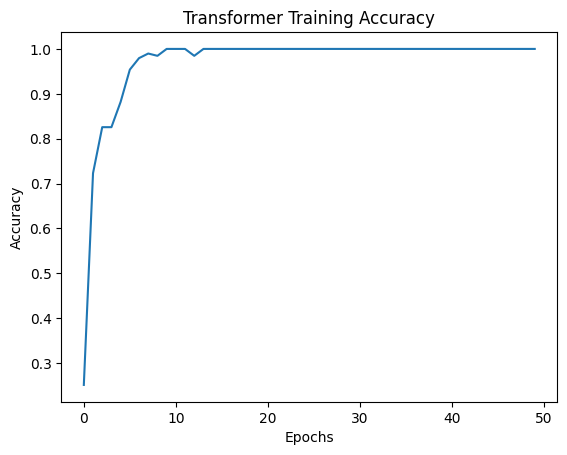

In [ ]:

import matplotlib.pyplot as plt

plt.plot(history.history["accuracy"])
plt.title("Transformer Training Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.show()
